In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [5]:
columns = ['evid','rhoA_threshold','index','b_ch','b','pt1_ch','pt2_ch','y1_ch','y2_ch','phi1_ch','phi2_ch','j1_ch','j2_ch','pt1','pt2','y1','y2','phi1','phi2','j1','j2','njet','pt','eta','phi','n','n_bckgrd']

In [8]:
weights = np.array([3.567450e-05, 1.142115e-04, 4.724955e-04, 1.993005e-03, 8.872100e-03, 4.341665e-02, 2.500510e-01,\
                    1.898125e+00, 1.278655e+01])

In [76]:
ptcut = [30,40,50,60,70,80,90,100,2000]

In [77]:
dataframes = []
files = ['/home/ys668/project/other_output/rc/isobar/toy_model/jet_in_bckgrd_50pthat1000.txt', \
         '/home/ys668/project/other_output/rc/isobar/toy_model/jet_in_bckgrd_45pthat50.txt', \
         '/home/ys668/project/other_output/rc/isobar/toy_model/jet_in_bckgrd_40pthat45.txt', \
         '/home/ys668/project/other_output/rc/isobar/toy_model/jet_in_bckgrd_35pthat40.txt', \
         '/home/ys668/project/other_output/rc/isobar/toy_model/jet_in_bckgrd_30pthat35.txt', \
         '/home/ys668/project/other_output/rc/isobar/toy_model/jet_in_bckgrd_25pthat30.txt', \
         '/home/ys668/project/other_output/rc/isobar/toy_model/jet_in_bckgrd_20pthat25.txt', \
         '/home/ys668/project/other_output/rc/isobar/toy_model/jet_in_bckgrd_15pthat20.txt', \
         '/home/ys668/project/other_output/rc/isobar/toy_model/jet_in_bckgrd_11pthat15.txt']
for i in range(0, len(files)):
    dataframe = pd.read_csv(files[i], names=columns, low_memory=False)
    dataframe = applyCut(dataframe, 'pt < ' + str(ptcut[i]))
    dataframe['w'] = np.ones(dataframe.shape[0]) * weights[i]
    dataframes.append(dataframe)
df = pd.concat([df for df in dataframes])

In [78]:
df_j = applyCut(df, 'j1_ch == 1 and j2_ch == 1')
df_b = applyCut(df, 'j1_ch == 0 or j2_ch == 0')

In [94]:
max(df_b['pt2_ch'])

2.9038

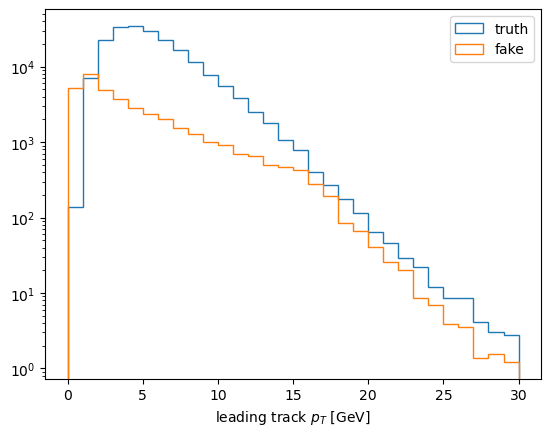

In [96]:
plt.hist(df_j['pt1_ch'], weights=df_j['w'], bins=np.arange(0,31), histtype='step', label='truth')
plt.hist(df_b['pt1_ch'], weights=df_b['w'], bins=np.arange(0,31), histtype='step', label='fake')
plt.xlabel('leading track $p_T$ [GeV]')
plt.yscale('log')
plt.legend()

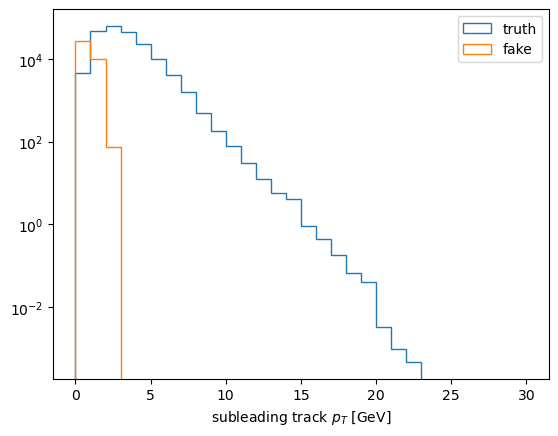

In [95]:
plt.hist(df_j['pt2_ch'], weights=df_j['w'], bins=np.arange(0,31), histtype='step', label='truth')
plt.hist(df_b['pt2_ch'], weights=df_b['w'], bins=np.arange(0,31), histtype='step', label='fake')
plt.xlabel('subleading track $p_T$ [GeV]')
plt.yscale('log')
plt.legend()

In [97]:
df_array = [ df[(df.pt>15) & (df.pt<20)],\
                df[(df.pt>20) & (df.pt<25)],\
                df[(df.pt>25) & (df.pt<30)],\
                df[(df.pt>30) & (df.pt<40)] ]

In [79]:
df_j_array = [ df_j[(df_j.pt>15) & (df_j.pt<20)],\
                df_j[(df_j.pt>20) & (df_j.pt<25)],\
                df_j[(df_j.pt>25) & (df_j.pt<30)],\
                df_j[(df_j.pt>30) & (df_j.pt<40)] ]

In [80]:
df_b_array = [ df_b[(df_b.pt>15) & (df_b.pt<20)],\
                df_b[(df_b.pt>20) & (df_b.pt<25)],\
                df_b[(df_b.pt>25) & (df_b.pt<30)],\
                df_b[(df_b.pt>30) & (df_b.pt<40)] ]

In [98]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

In [81]:
rc_j_array = []
rc_err_j_array = []
for i in range(0, len(df_j_array)):
    rc_j_array.append(getRcAndErr(df_j_array[i], 'b_ch')[0])
    rc_err_j_array.append(getRcAndErr(df_j_array[i], 'b_ch')[1])

In [82]:
rc_b_array = []
rc_err_b_array = []
for i in range(0, len(df_b_array)):
    rc_b_array.append(getRcAndErr(df_b_array[i], 'b_ch')[0])
    rc_err_b_array.append(getRcAndErr(df_b_array[i], 'b_ch')[1])

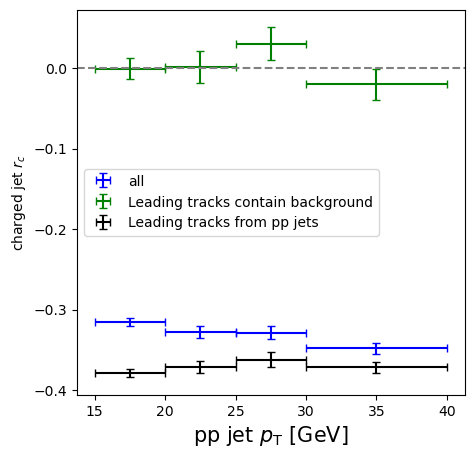

In [100]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_array, capsize=3, color='b', ls='none', label='all')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_b_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_b_array, capsize=3, color='g', ls='none', label='Leading tracks contain background')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_j_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_j_array, capsize=3, color='k', ls='none', label='Leading tracks from pp jets')
plt.xlabel('pp jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
#plt.ylim(-0.6,1)
plt.legend(loc='center left')

In [101]:
df_j_hc = applyCut(df_j, 'pt2_ch > 2')
df_b_hc = applyCut(df_b, 'pt2_ch > 2')

In [102]:
df_j_hc_array = [ df_j_hc[(df_j_hc.pt>15) & (df_j_hc.pt<20)],\
                df_j_hc[(df_j_hc.pt>20) & (df_j_hc.pt<25)],\
                df_j_hc[(df_j_hc.pt>25) & (df_j_hc.pt<30)],\
                df_j_hc[(df_j_hc.pt>30) & (df_j_hc.pt<40)] ]

In [103]:
df_b_hc_array = [ df_b_hc[(df_b_hc.pt>15) & (df_b_hc.pt<20)] ,\
                df_b_hc[(df_b_hc.pt>20) & (df_b_hc.pt<25)] ,\
                df_b_hc[(df_b_hc.pt>25) & (df_b_hc.pt<30)] ,\
                df_b_hc[(df_b_hc.pt>30) & (df_b_hc.pt<40)] ]

In [104]:
rc_j_hc_array = []
rc_err_j_hc_array = []
for i in range(0, len(df_j_hc_array)):
    rc_j_hc_array.append(getRcAndErr(df_j_hc_array[i], 'b_ch')[0])
    rc_err_j_hc_array.append(getRcAndErr(df_j_hc_array[i], 'b_ch')[1])

In [105]:
rc_b_hc_array = []
rc_err_b_hc_array = []
for i in range(0, len(df_b_hc_array)):
    rc_b_hc_array.append(getRcAndErr(df_b_hc_array[i], 'b_ch')[0])
    rc_err_b_hc_array.append(getRcAndErr(df_b_hc_array[i], 'b_ch')[1])

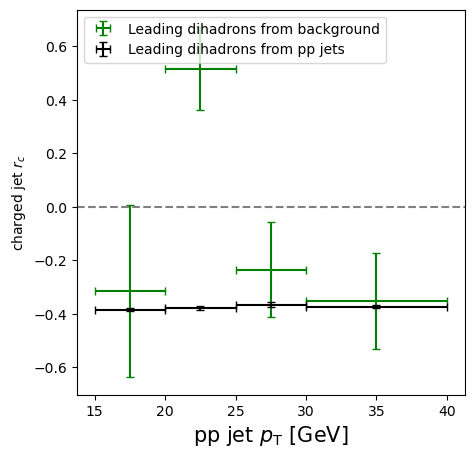

In [106]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_b_hc_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_b_hc_array, capsize=3, color='g', ls='none', label='Leading dihadrons from background')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_j_hc_array, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_j_hc_array, capsize=3, color='k', ls='none', label='Leading dihadrons from pp jets')
plt.xlabel('pp jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
#plt.ylim(-0.6,1)
plt.legend(loc='upper left')